In [2]:
from tbparse import SummaryReader
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path
import os
from tqdm import tqdm

In [3]:
logdir = "runs"
reader = SummaryReader(logdir, extra_columns={"dir_name"})

In [4]:
data = reader.scalars
data.rename(columns={"dir_name": "run_name"}, inplace=True)
data["run_category"] = data["run_name"].str.split("_").str[:-2].str.join("_")
data["run_seed"] = data["run_name"].str.split("_").str[-1]
data["aux_weight"] = data["run_name"].str.split("_").str[-2].str[1:]
data

,step,tag,value,run_name,run_category,run_seed,aux_weight
0,0,aux/r2_score_angular_velocity_y,-36.760838,all_w0.1_s0,all,s0,0.1
1,1,aux/r2_score_angular_velocity_y,-12.740454,all_w0.1_s0,all,s0,0.1
2,2,aux/r2_score_angular_velocity_y,-0.709868,all_w0.1_s0,all,s0,0.1
3,3,aux/r2_score_angular_velocity_y,-0.812792,all_w0.1_s0,all,s0,0.1
4,4,aux/r2_score_angular_velocity_y,-0.419878,all_w0.1_s0,all,s0,0.1
...,...,...,...,...,...,...,...
5562577,595,total_loss,0.777437,wheel_slip_rear_lateral_w1_s2,wheel_slip_rear_lateral,s2,1
5562578,596,total_loss,0.807580,wheel_slip_rear_lateral_w1_s2,wheel_slip_rear_lateral,s2,1
5562579,597,total_loss,0.793396,wheel_slip_rear_lateral_w1_s2,wheel_slip_rear_lateral,s2,1
5562580,598,total_loss,0.767980,wheel_slip_rear_lateral_w1_s2,wheel_slip_rear_lateral,s2,1


In [5]:
data[data["run_category"] == "baseline"]["run_seed"].unique()

array(['s0', 's1', 's2', 's3', 's4', 's5', 's6'], dtype=object)

In [6]:
data["tag"].unique()

array(['aux/r2_score_angular_velocity_y',
       'aux/r2_score_track_curvature_0_50',
       'aux/r2_score_track_curvature_1_00',
       'aux/r2_score_track_curvature_1_50',
       'aux/r2_score_track_curvature_2_00',
       'aux/r2_score_track_curvature_2_50',
       'aux/r2_score_track_curvature_3_00',
       'aux/r2_score_track_curvature_3_50',
       'aux/r2_score_track_curvature_4_00',
       'aux/r2_score_track_curvature_4_50',
       'aux/r2_score_track_curvature_5_00',
       'aux/r2_score_track_curvature_5_50',
       'aux/r2_score_track_curvature_6_00',
       'aux/r2_score_track_curvature_6_50',
       'aux/r2_score_track_curvature_7_00',
       'aux/r2_score_track_curvature_7_50',
       'aux/r2_score_track_curvature_8_00',
       'aux/r2_score_velocity_forward', 'aux/r2_score_velocity_lateral',
       'aux/r2_score_wheel_slip_forward_back_left',
       'aux/r2_score_wheel_slip_forward_back_right',
       'aux/r2_score_wheel_slip_forward_front_left',
       'aux/r2_score_wh

In [9]:
def auc(g):
    return np.trapezoid(g["value"], g["step"])

completed_runs = data[data["step"] == 599]

rewards = data[(data["tag"] == "reward/mean")].sort_values("step")
# get only the ones that are finished
rewards = rewards[rewards.groupby("run_name")["step"].transform("max") >= 599]

auc_df = (
    rewards.groupby(["run_category", "aux_weight", "run_seed"])
           .apply(auc, include_groups=False)
           .rename("auc")
           .reset_index()
)
auc_df

,run_category,aux_weight,run_seed,auc
0,all,0.1,s0,72.570749
1,all,0.1,s1,75.059271
2,all,0.1,s2,76.228633
3,all,0.3,s0,67.416031
4,all,0.3,s1,70.948828
...,...,...,...,...
101,wheel_slip_rear_lateral,0.3,s1,82.225198
102,wheel_slip_rear_lateral,0.3,s2,32.774071
103,wheel_slip_rear_lateral,1,s0,77.952068
104,wheel_slip_rear_lateral,1,s1,32.589767


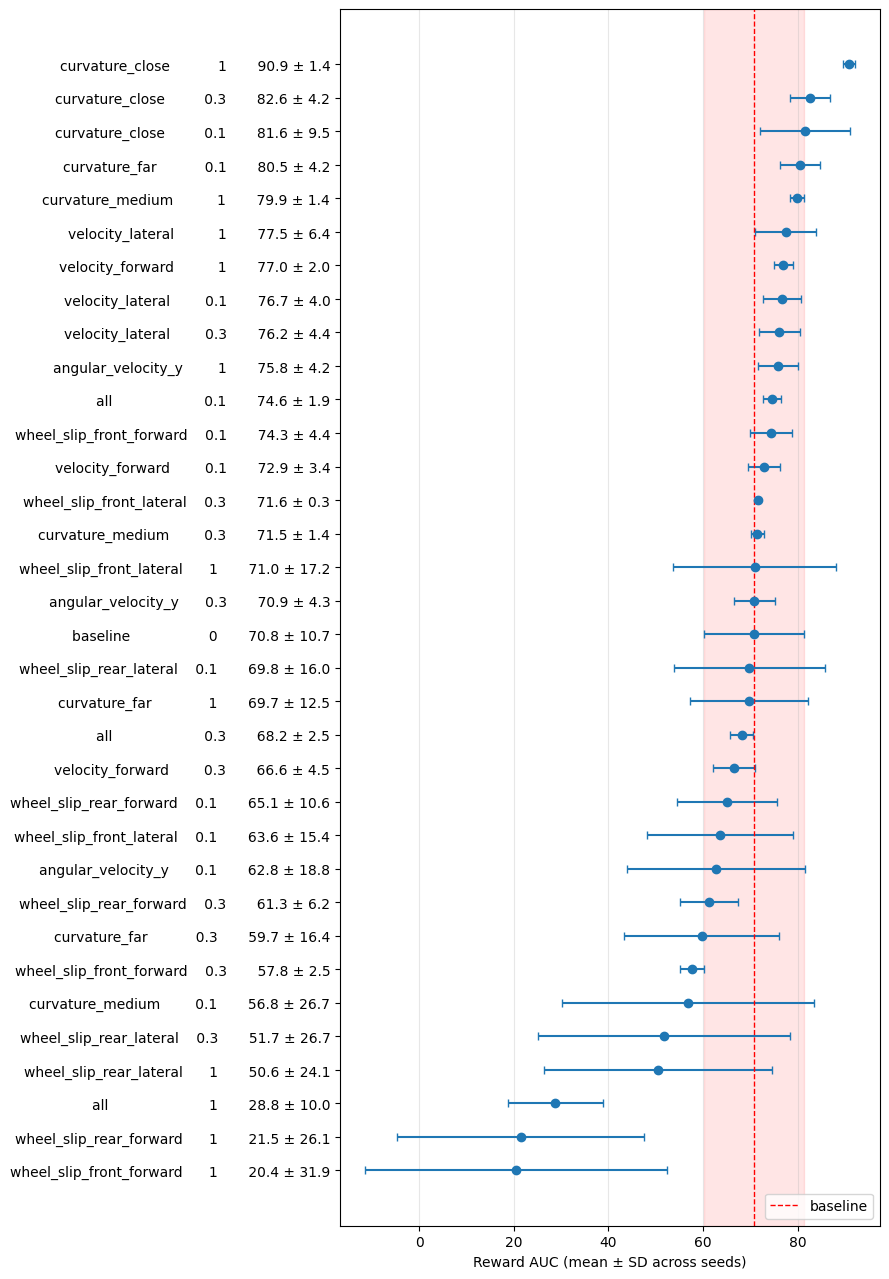

In [ ]:
summary = (
    auc_df.groupby(["run_category", "aux_weight"])["auc"]
          .agg(["mean", "std"])
          .reset_index()
          .sort_values("mean")
          .reset_index(drop=True)
)

labels = [
    f"{r.run_category:<20} {r.aux_weight:>6}   {r['mean']:8.1f} ± {r['std']:.1f}"
    for _, r in summary.iterrows()
]

fig, ax = plt.subplots(figsize=(9, 0.35 * len(summary) + 1))
ax.errorbar(summary["mean"], summary.index, xerr=summary["std"], fmt="o", capsize=3)

ax.set_yticks(summary.index, labels)
ax.set_xlabel("Reward AUC (mean ± SD across seeds)")
ax.grid(axis="x", alpha=0.3)

base = summary[summary["run_category"] == "baseline"].iloc[0]

ax.axvline(base["mean"], color="red", ls="--", lw=1, label="baseline")
ax.axvspan(base["mean"] - base["std"], base["mean"] + base["std"], color="red", alpha=0.1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/figures/"
".pdf")